# Policy analysis: protecting economic activity from rising heat

This notebook turns the challenge forecasts into a short, evidence-based policy idea. It compares each city's submitted 2019–2025 heat forecasts with its 2010–2018 observed climate, then joins those city-level changes to state economic indicators from BEA.

**Policy question:** Where could heat resilience help protect people and economic activity, and what should governments and employers do?

**Interpretation limits:** The weather forecasts are the team's submitted predictions, not observed 2019–2025 outcomes. City observations are averaged equally within states (not population weighted). State GDP and per-capita personal income are economic context, not measures of climate damages, household vulnerability, or causal effects. We use 2018 economic values to keep the comparison anchored at the challenge forecast cutoff.


## 1. Load the challenge and BEA data

Inputs are already included in this repository. Historical climate observations stop in 2018; all later climate values come from `submission.csv`. BEA's state GDP and state personal-income tables provide 2018 real GDP and per-capita personal income. City-to-state matching uses the climate-division state's two-digit FIPS code.


In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "submission.csv").exists():
    raise FileNotFoundError("Run this notebook from the repository root.")

submission = pd.read_csv(ROOT / "submission.csv", dtype={"city_id": "string"})
annual = pd.read_parquet(ROOT / "data" / "annual_indices.parquet")
city_states = pd.read_parquet(ROOT / "data" / "city_climate_divisions.parquet")
state_gdp = pd.read_parquet(ROOT / "data" / "us_gdp" / "SAGDP.parquet")
state_income = pd.read_parquet(ROOT / "data" / "us_personal_income" / "SAINC.parquet")

print(f"Forecast rows: {len(submission):,}; cities: {submission.city_id.nunique():,}")
print(f"Historical climate years: {annual.Year.min()}–{annual.Year.max()}")
print(f"Forecast years: {submission.year.min()}–{submission.year.max()}")


Forecast rows: 5,880; cities: 210
Historical climate years: 1851–2018
Forecast years: 2019–2025


## 2. Measure forecast heat change by city

For each city, calculate the average submitted forecast for 2019–2025 and subtract its 2010–2018 observed average. The two heat indicators are **cooling degree days (CDD)** and **hottest day of the year**. CDD is a measure of demand for cooling; the hottest-day metric highlights extreme-heat exposure. The difference is descriptive and is not an estimate of climate-change attribution.


In [2]:
historical_columns = {
    "cdd": "cdd",
    "hottest_day_temp": "Max Tmax",
}

historical_heat = (
    annual.loc[annual["Year"].between(2010, 2018)]
    .groupby("ID")[[*historical_columns.values()]]
    .mean()
    .rename(columns={source: f"{metric}_observed" for metric, source in historical_columns.items()})
)
historical_heat.index.name = "city_id"

forecast_heat = (
    submission.loc[
        submission["metric"].isin(historical_columns)
        & submission["year"].between(2019, 2025),
        ["city_id", "year", "metric", "predicted_value"],
    ]
    .groupby(["city_id", "metric"])["predicted_value"]
    .mean()
    .unstack("metric")
)

city_heat = forecast_heat.join(historical_heat, how="inner")
for metric in historical_columns:
    observed_column = f"{metric}_observed"
    city_heat[f"{metric}_change"] = city_heat[metric] - city_heat[observed_column]

city_heat = city_heat.reset_index().merge(
    city_states[["ID", "division_STATE", "division_STATE_FIPS"]].drop_duplicates("ID"),
    left_on="city_id",
    right_on="ID",
    how="left",
    validate="one_to_one",
)
city_heat["state_fips"] = city_heat["division_STATE_FIPS"].astype("string").str.zfill(2)

if city_heat["state_fips"].isna().any():
    missing = city_heat.loc[city_heat["state_fips"].isna(), "city_id"].tolist()
    raise ValueError(f"Could not map forecast cities to a state: {missing[:10]}")

city_heat[["city_id", "division_STATE", "cdd_change", "hottest_day_temp_change"]].head()


,city_id,division_STATE,cdd_change,hottest_day_temp_change
0,USC00042863,California,174.108706,0.213795
1,USC00166584,Louisiana,50.958383,0.198870
2,USC00280734,New Jersey,154.291130,-0.071090
3,USC00286055,New Jersey,7.659450,-1.643608
4,USC00356749,Oregon,146.376525,1.192457


## 3. Add state economic context

BEA `SAGDP` line 1 is real GDP in millions of chained 2017 dollars. BEA `SAINC` line 3 is per-capita personal income in dollars. The code selects 2018 values and joins by state FIPS. GDP indicates the approximate scale of state economic activity; per-capita income gives a broad income-level context. Neither represents who is most exposed or least able to adapt.


In [3]:
def state_indicator(frame, table_name, line_code, value_name):
    selected = frame.loc[
        (frame["TableName"] == table_name)
        & (frame["LineCode"].astype(float) == line_code)
        & frame["GeoFIPS"].astype("string").str.fullmatch(r"\d{5}")
        & frame["GeoFIPS"].astype("string").str.endswith("000"),
        ["GeoFIPS", "GeoName", "2018"],
    ].copy()
    selected["state_fips"] = selected["GeoFIPS"].astype("string").str[:2]
    selected[value_name] = pd.to_numeric(selected["2018"], errors="coerce")
    return selected[["state_fips", "GeoName", value_name]].drop_duplicates("state_fips")


gdp_2018 = state_indicator(state_gdp, "SAGDP1", 1, "real_gdp_millions_2017_dollars")
income_2018 = state_indicator(state_income, "SAINC1", 3, "per_capita_income_dollars")
economy = gdp_2018[["state_fips", "GeoName", "real_gdp_millions_2017_dollars"]].merge(
    income_2018[["state_fips", "per_capita_income_dollars"]],
    on="state_fips",
    how="outer",
    validate="one_to_one",
)

state_heat = (
    city_heat.groupby("state_fips", as_index=False)
    .agg(
        state=("division_STATE", "first"),
        cities=("city_id", "nunique"),
        mean_cdd_change=("cdd_change", "mean"),
        mean_hottest_day_change=("hottest_day_temp_change", "mean"),
    )
)
analysis = state_heat.merge(economy, on="state_fips", how="left", validate="one_to_one")
analysis["real_gdp_billions_2017_dollars"] = (
    analysis["real_gdp_millions_2017_dollars"] / 1_000
)

print(f"States represented by challenge cities: {analysis.state.nunique()}")
print(f"States with matched GDP and income: {analysis.dropna(subset=['real_gdp_billions_2017_dollars', 'per_capita_income_dollars']).state.nunique()}")
analysis.sort_values("mean_cdd_change", ascending=False).head(10)[
    ["state", "cities", "mean_cdd_change", "mean_hottest_day_change", "real_gdp_billions_2017_dollars", "per_capita_income_dollars"]
]


States represented by challenge cities: 46
States with matched GDP and income: 46


,state,cities,mean_cdd_change,mean_hottest_day_change,real_gdp_billions_2017_dollars,per_capita_income_dollars
3,California,12,172.081426,0.192864,2850.6088,60994.0
1,Arizona,4,153.820015,0.206189,346.3757,45223.0
35,South Carolina,3,147.677475,-0.042760,231.654,43831.0
24,Nevada,4,147.380492,0.336293,168.6352,49307.0
33,Oregon,6,145.480465,0.667202,234.2775,50198.0
39,Utah,1,142.631987,0.048052,182.0955,45403.0
42,Washington,5,133.544032,0.541366,561.7187,59838.0
22,Montana,5,131.690237,0.392581,49.4379,47211.0
25,New Hampshire,2,109.491820,-0.446066,82.2678,60267.0
36,South Dakota,4,103.889670,0.272585,51.8937,51541.0


## 4. Compare heat exposure and economic scale

The scatterplot helps distinguish states with larger mean forecast CDD increases from those with larger economies. Bubble color shows 2018 per-capita personal income; it is not a vulnerability score. Each point is a state-level average across its challenge cities, with unequal numbers of cities per state.


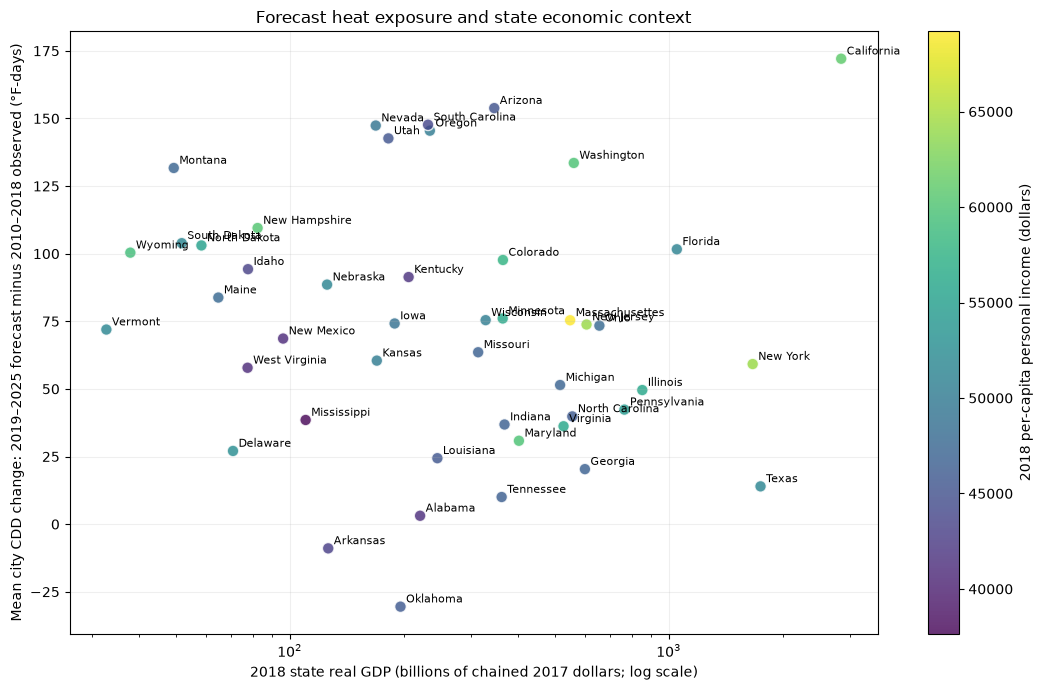

In [4]:
plot_data = analysis.dropna(
    subset=["mean_cdd_change", "real_gdp_billions_2017_dollars", "per_capita_income_dollars"]
).copy()
fig, ax = plt.subplots(figsize=(11, 7))
points = ax.scatter(
    plot_data["real_gdp_billions_2017_dollars"],
    plot_data["mean_cdd_change"],
    c=plot_data["per_capita_income_dollars"],
    cmap="viridis",
    s=70,
    alpha=0.8,
    edgecolor="white",
)
for row in plot_data.itertuples():
    ax.annotate(row.state, (row.real_gdp_billions_2017_dollars, row.mean_cdd_change), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("2018 state real GDP (billions of chained 2017 dollars; log scale)")
ax.set_ylabel("Mean city CDD change: 2019–2025 forecast minus 2010–2018 observed (°F-days)")
ax.set_title("Forecast heat exposure and state economic context")
fig.colorbar(points, ax=ax, label="2018 per-capita personal income (dollars)")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


## 5. Map: state GDP and forecast temperature

The map combines 2018 state real GDP (state shading) with each city's mean forecast annual average temperature for 2019–2025 (point color). This highlights where substantial economic activity and warmer forecast conditions overlap; GDP is context for the scale of activity, not an estimate of heat-related losses. Boundaries are the included NOAA climate divisions dissolved to states, so the map shows the contiguous U.S.


In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm

forecast_temperature = (
    submission.loc[
        submission["metric"].eq("annual_avg_temp")
        & submission["year"].between(2019, 2025)
    ]
    .groupby("city_id", as_index=False)["predicted_value"]
    .mean()
    .rename(columns={"predicted_value": "forecast_avg_temp_f"})
)
city_map = city_heat[["city_id", "state_fips"]].merge(
    forecast_temperature, on="city_id", validate="one_to_one"
).merge(
    city_states[["ID", "Lat", "Lon"]].drop_duplicates("ID"),
    left_on="city_id",
    right_on="ID",
    validate="one_to_one",
)
city_map = gpd.GeoDataFrame(
    city_map,
    geometry=gpd.points_from_xy(city_map["Lon"], city_map["Lat"]),
    crs="EPSG:4326",
).to_crs("EPSG:5070")

boundary_path = ROOT / "data" / "CONUS_CLIMATE_DIVISIONS.shp.zip"
divisions = gpd.read_file(
    f"zip://{boundary_path}!GIS.OFFICIAL_CLIM_DIVISIONS.shp"
).to_crs("EPSG:5070")
state_boundaries = divisions.dissolve(by="STATE_FIPS", as_index=False)
city_map = gpd.sjoin(
    city_map,
    state_boundaries[["geometry"]],
    how="inner",
    predicate="within",
)
state_boundaries["state_fips"] = state_boundaries["STATE_FIPS"].astype("string").str.zfill(2)
state_map = state_boundaries.merge(
    analysis[["state_fips", "real_gdp_billions_2017_dollars"]],
    on="state_fips",
    how="left",
    validate="one_to_one",
)

gdp_values = state_map["real_gdp_billions_2017_dollars"].dropna()
gdp_norm = LogNorm(vmin=gdp_values.min(), vmax=gdp_values.max())
temperature_norm = plt.Normalize(
    city_map["forecast_avg_temp_f"].min(), city_map["forecast_avg_temp_f"].max()
)
fig = plt.figure(figsize=(13, 8))
ax = fig.add_axes([0.02, 0.23, 0.96, 0.70])
state_map.plot(
    column="real_gdp_billions_2017_dollars",
    cmap="Blues",
    norm=gdp_norm,
    edgecolor="white",
    linewidth=0.6,
    ax=ax,
    missing_kwds={"color": "#eeeeee"},
)
city_map.plot(
    ax=ax,
    column="forecast_avg_temp_f",
    cmap="YlOrRd",
    norm=temperature_norm,
    markersize=22,
    edgecolor="white",
    linewidth=0.35,
    alpha=0.9,
)
gdp_colorbar = fig.colorbar(
    ScalarMappable(norm=gdp_norm, cmap="Blues"),
    cax=fig.add_axes([0.12, 0.10, 0.34, 0.025]),
    orientation="horizontal",
)
gdp_colorbar.set_label("2018 real GDP (billions of chained 2017 dollars; log scale)", labelpad=5)
temperature_colorbar = fig.colorbar(
    ScalarMappable(norm=temperature_norm, cmap="YlOrRd"),
    cax=fig.add_axes([0.55, 0.10, 0.34, 0.025]),
    orientation="horizontal",
)
temperature_colorbar.set_label("Mean forecast annual average temperature, 2019–2025 (°F)", labelpad=5)
ax.set_title("2019–2025 forecast temperatures and state GDP (contiguous U.S.)")
ax.set_axis_off()
map_path = ROOT / "policy_heat_economy_map.png"
fig.savefig(map_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved map to {map_path}")


## 6. Policy idea for the submission

**Heat-resilient work and essential services:** State and local governments should target heat-resilience pilots to communities facing high forecast increases in cooling demand, while employers and utilities protect workers and keep essential services operating during extreme heat. Pair building efficiency and cool-roof/shade retrofits with accessible cooling centers, heat-health alerts, and enforceable work-rest-water protections for outdoor workers. Prioritize public facilities and small businesses that cannot readily fund upgrades; use grants or utility incentives so the transition does not shift costs onto lower-income households.

Use the ranked results below to name the states where pilot planning could begin. GDP helps indicate the scale of economic activity that continuity planning may protect; per-capita income is context for local affordability, not a substitute for neighborhood-level poverty, occupation, age, health, housing, or energy-burden data. Before targeting funds, add those local indicators and direct outreach to affected workers and residents. Evaluate the pilot using heat-related illness, workplace disruption, cooling access, and energy burden—not GDP alone.


In [5]:
priority_states = analysis.sort_values("mean_cdd_change", ascending=False).head(8)
priority_states[[
    "state",
    "cities",
    "mean_cdd_change",
    "mean_hottest_day_change",
    "real_gdp_billions_2017_dollars",
    "per_capita_income_dollars",
]].copy().round({
    "mean_cdd_change": 0,
    "mean_hottest_day_change": 1,
    "real_gdp_billions_2017_dollars": 1,
    "per_capita_income_dollars": 0,
})


,state,cities,mean_cdd_change,mean_hottest_day_change,real_gdp_billions_2017_dollars,per_capita_income_dollars
3,California,12,172.0,0.2,2850.6,60994.0
1,Arizona,4,154.0,0.2,346.4,45223.0
35,South Carolina,3,148.0,-0.0,231.7,43831.0
24,Nevada,4,147.0,0.3,168.6,49307.0
33,Oregon,6,145.0,0.7,234.3,50198.0
39,Utah,1,143.0,0.0,182.1,45403.0
42,Washington,5,134.0,0.5,561.7,59838.0
22,Montana,5,132.0,0.4,49.4,47211.0


## Sources and reproducibility

- Challenge historical climate: `data/annual_indices.parquet` (observations through 2018).
- Challenge predictions: `submission.csv` (team forecasts for 2019–2025).
- City-state crosswalk: `data/city_climate_divisions.parquet` (NOAA climate division geography).
- State GDP: BEA `SAGDP` table, line 1, 2018 real GDP (chained 2017 dollars).
- State income: BEA `SAINC` table, line 3, 2018 per-capita personal income.

The BEA values are used only for the policy analysis; they are not forecast features. Because state climate exposure is a simple average over challenge cities, results are not state population-weighted. Forecast-vs-history changes are scenario comparisons from this team's model, not claims about the subsequently observed weather or measured economic impacts.
